# Brazil STAR household microgrids

This notebook lists the four released households, loads one household's battery files, and plots battery voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('brazil_star')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('brazil_star')
display(released)

,unit,household,battery_days,pv_days,iam_days,battery_rows,first,last,battery_time_invalid
0,STAR-A,STAR-A,138,142,7,162170,2018-06-08 11:13:38,2019-02-14 13:01:18,2315
1,STAR-B,STAR-B,187,176,5,217358,2018-07-17 12:02:19,2019-02-28 10:18:59,912
2,STAR-C,STAR-C,64,59,2,79584,2018-01-02 13:12:16,2018-10-26 12:46:00,568
3,STAR-D,STAR-D,38,0,4,40854,2018-03-28 06:31:11,2018-11-28 11:53:52,216


Each row is one household with its days of battery, PV and appliance files and its first and last valid battery time. Times before 2017 are clock resets and are left out of the span.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('brazil_star', unit='STAR-A', system='Battery')
print(frame.shape)
display(frame.head())

(162170, 11)


,file,Time,Current,AmpereHours,SOC,NumChargeCycles,NumFullDischarge,Voltage,Power,DischargeEnergy,ChargeEnergy
0,2018-06-08_STAR-A_Battery.csv,2018-06-08 11:13:38,8747.0,0.0,1000.0,0.0,0.0,26375.0,231.0,159.0,4.0
1,2018-06-08_STAR-A_Battery.csv,2018-06-08 11:29:46,12183.0,0.0,1000.0,0.0,0.0,26796.0,326.0,159.0,15.0
2,2018-06-08_STAR-A_Battery.csv,2018-06-08 11:48:19,11960.0,0.0,1000.0,0.0,0.0,26114.0,312.0,159.0,10.0
3,2018-06-08_STAR-A_Battery.csv,2018-06-08 11:49:19,11935.0,0.0,1000.0,0.0,0.0,26110.0,312.0,159.0,10.0
4,2018-06-08_STAR-A_Battery.csv,2018-06-08 11:50:19,11935.0,0.0,1000.0,0.0,0.0,26110.0,312.0,159.0,10.0


All 138 daily battery files of STAR-A, one row per minute, with the file name added. Current is in mA, voltage in mV and SOC in tenths of a percent, as the data show.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['Current', 'AmpereHours', 'SOC', 'Voltage', 'Power']].describe().T)

,count,mean,std,min,25%,50%,75%,max
Current,162063.0,4.728216e+03,7.830192e+03,0.000000e+00,0.0,0.0,6421.0,5.180900e+04
AmpereHours,161177.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000e+00
SOC,161701.0,-6.850705e+06,3.190292e+08,-1.322993e+10,1000.0,1000.0,1000.0,1.531171e+09
Voltage,161905.0,2.446663e+04,2.570001e+03,0.000000e+00,23945.0,24600.0,25403.0,2.878700e+04
Power,162090.0,1.241983e+02,2.048968e+02,0.000000e+00,0.0,3.0,164.0,9.470000e+02


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

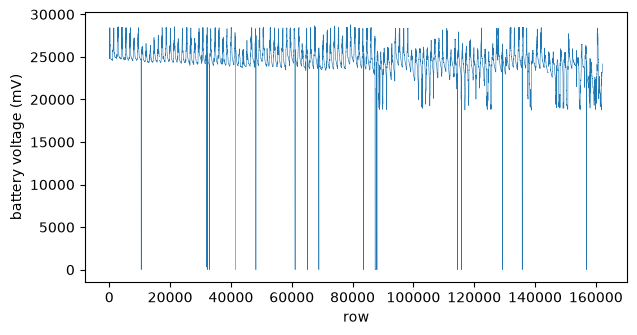

In [4]:
ax = frame['Voltage'].plot(figsize=(7, 3.5), lw=0.4)
ax.set_xlabel('row')
ax.set_ylabel('battery voltage (mV)')
plt.show()

STAR-A's battery voltage sits near 24,600 mV (24.6 V, the median) over the 138 days, with some zero readings left as released.